**Célula 0** — Carrega a imagem `face_image02.avif` com OpenCV, mostra ela e pega as dimensões: `n=800` (linhas), `m=800` (colunas), `c=3` (canais de cor, BGR).

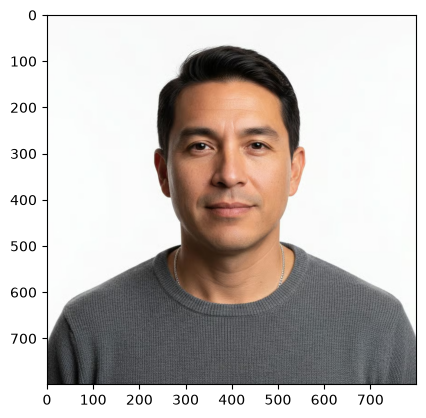

<Figure size 1000x600 with 0 Axes>

linhas: 800
colunas: 800
cores: 3


In [4]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

img = cv2.imread('../images/face_image02.avif')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.figure(figsize=(10, 6))
plt.show()

K = 2
n, m, c = img.shape
print(f'linhas: {n}\ncolunas: {m}\ncores: {c}')


**Célula 1** — Separa a imagem nos 3 planos de cor (B, G, R) e mostra cada um como imagem em escala de cinza. Guarda os planos em `plano`.

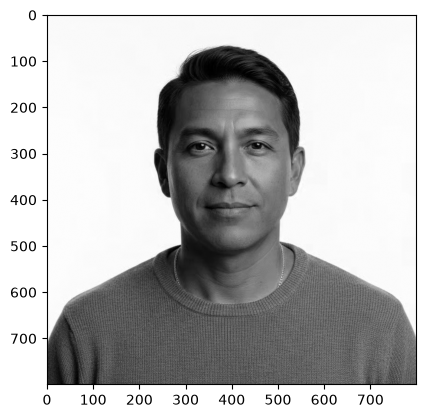

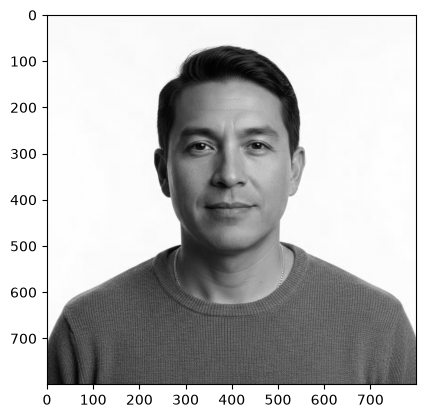

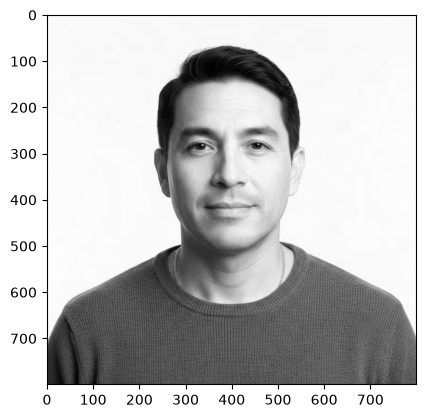

In [5]:
PLANO = []
FAIXA = []

for cor in range(c):
    PLANO.append(img[:,:,cor])
    plt.figure()
    plt.imshow(PLANO[-1], cmap="gray")
    plt.show()

**Célula 2** — Achata (`flatten()`) cada plano de cor em um vetor 1D e plota os valores de intensidade de cada pixel em sequência. **Bug secundário aqui:** o código usa `plano[-1]` dentro do loop `for cor in range(c)`, ou seja, sempre pega o **último** plano (índice 2, correspondente ao canal R) 3 vezes, em vez de `plano[cor]`. Isso não afeta diretamente o "0 0 0 0", mas está errado — `faixa` acaba com 3 cópias do mesmo canal.

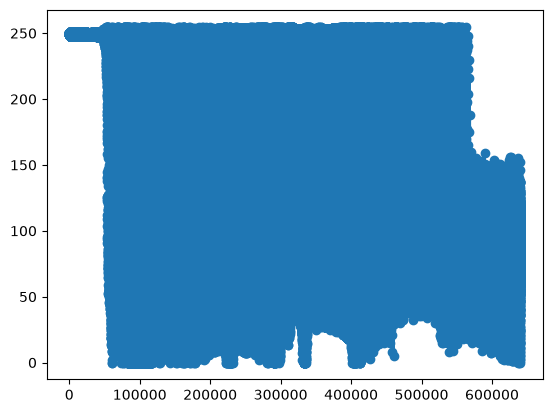

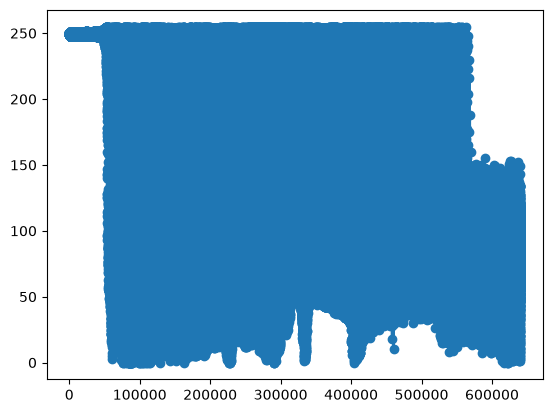

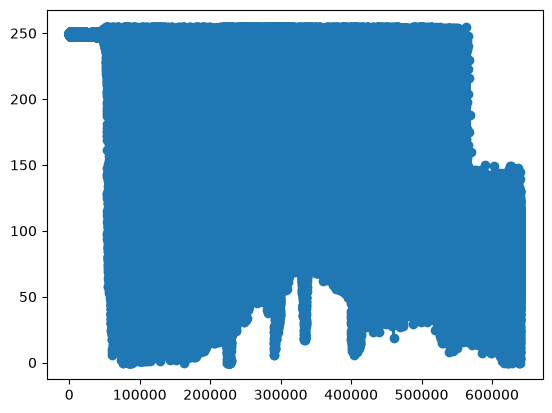

In [6]:
for cor in range(c):
    
    FAIXA.append(PLANO[cor].flatten())
    plt.figure()
    plt.plot(FAIXA[-1])
    plt.scatter(np.arange(len(FAIXA[-1])), FAIXA[-1])


**Célula 3** — Prepara o K-means manual: `K=2` clusters, `pixels` é a imagem achatada em `(640000, 3)` (cada linha é um pixel RGB).

In [16]:
K = 2
centroid = []
pixels = img.reshape(-1, 3)
npx = len(pixels)
print(npx)
print(pixels)
# for k in range(K):
#     px = np.random.randint(0, npx)

640000
[[250 250 250]
 [250 250 250]
 [250 250 250]
 ...
 [115 112 108]
 [ 87  84  80]
 [ 94  91  87]]


**Célula 4** — Sorteia 2 pixels aleatórios da imagem como centróides iniciais.


In [17]:
for k in range(K):
    px = np.random.randint(0, npx)
    centroid.append(pixels[px])
    print(px)
    print(centroid)


340002
[array([253, 254, 252], dtype=uint8)]
613808
[array([253, 254, 252], dtype=uint8), array([87, 83, 82], dtype=uint8)]


**Célula 5** — Converte `centroid` para array numpy.

In [18]:
centroid = np.array(centroid)
print(centroid)

[[253 254 252]
 [ 87  83  82]]


## Função da Célula 6

Essa célula é o **coração do algoritmo de K-means**: a etapa de **atribuição de clusters** (assignment step).

Para cada um dos 640.000 pixels da imagem, o código:
1. Monta o vetor de cor `v = [R, G, B]` daquele pixel (usando os valores extraídos nas células anteriores);
2. Calcula a **distância euclidiana** (`np.linalg.norm`) entre esse pixel e cada um dos `K` centróides sorteados (Célula 4/5);
3. Descobre qual centróide está mais próximo (`argmin(d)`);
4. Deveria guardar esse pixel na lista do cluster correspondente (`CLUSTER[cluster]`) — que é justamente o passo que estava quebrado pelo bug do `.append` sem argumento.

Em resumo: essa célula decide, pixel a pixel, **"esta cor é mais parecida com o centróide 0 ou com o centróide 1?"** e deveria agrupar os pixels de acordo com a resposta.


In [20]:
CLUSTER = [[] for _ in range(K)]
for px in range(npx):
    v = np.array([faixa[0][px], faixa[1][px], faixa[2][px]])
    d = []
    
    for k in range(K):
        d.append(np.linalg.norm(v - centroid[k]))
        
    cluster = int(np.argmin(d))
    CLUSTER[cluster].append(px)

for k in range(K):
    print(f"Cluster {k}: {len(CLUSTER[0]), len(CLUSTER[1])} pixels")

Cluster 0: (131747, 508253) pixels
Cluster 1: (131747, 508253) pixels



## Contexto geral da aplicação

O notebook implementa, **do zero (sem usar `sklearn.cluster.KMeans`)**, o algoritmo de **K-means aplicado à cor de uma imagem** — uma técnica clássica de **segmentação de imagens por cor** / **quantização de cores**. O fluxo completo é:

| Etapa | Célula | O que faz |
|---|---|---|
| 1. Carregar imagem | 0 | Lê a imagem e extrai dimensões (altura, largura, canais) |
| 2. Separar canais | 1 | Isola os planos B, G, R individualmente |
| 3. Vetorizar | 2 | Achata cada canal num vetor 1D (uma "faixa" de intensidades) |
| 4. Preparar pixels | 3 | Reorganiza a imagem como uma lista de pontos 3D (`[R,G,B]` por pixel) |
| 5. Inicializar centróides | 4-5 | Sorteia K pixels aleatórios como "chute inicial" dos centros dos clusters |
| **6. Atribuir clusters** | **6** | **Classifica cada pixel no centróide mais próximo (etapa que você perguntou)** |
| 7. (faltando) Recalcular centróides | — | Normalmente o K-means teria mais uma etapa aqui: recalcular a média de cada cluster e repetir a atribuição até convergir — isso ainda não está implementado no notebook |

## Usabilidades práticas dessa técnica

Agrupar pixels por similaridade de cor (K-means em espaço RGB) tem aplicações reais como:
- **Compressão/quantização de cores**: reduzir uma imagem de milhões de cores para só `K` cores dominantes (é assim que formatos como GIF, com paleta limitada, funcionavam);
- **Segmentação de imagem**: separar "objeto" de "fundo" quando eles têm cores bem distintas (ex: separar um rosto do fundo branco, como na imagem usada aqui);
- **Extração de paleta dominante**: identificar as cores principais de uma foto (usado em apps de design, e-commerce de moda, etc.);
- **Pré-processamento para outras tarefas de visão computacional**: simplificar a imagem antes de detecção de bordas, contornos ou reconhecimento de objetos.

**Ponto importante sobre o estado atual do notebook:** como só existe a etapa de atribuição (Célula 6) e falta a etapa de **recalcular os centróides como a média dos pixels de cada cluster** e repetir isso em várias iterações até estabilizar, o algoritmo ainda não é um K-means completo — é só a "primeira rodada" dele, usando centróides aleatórios sem refinamento. Se o objetivo da atividade for realmente segmentar a imagem em K cores, essa é a próxima peça que falta implementar, algo como:

```python
for iteracao in range(max_iteracoes):
    # 1. Atribuição (o que já existe na Célula 6, mas corrigido)
    CLUSTER = [[] for _ in range(K)]
    for px in range(npx):
        v = pixels[px]
        d = [np.linalg.norm(v - centroid[k]) for k in range(K)]
        cluster = int(np.argmin(d))
        CLUSTER[cluster].append(px)
    
    # 2. Atualização dos centróides (etapa que falta)
    novo_centroid = np.array([
        pixels[CLUSTER[k]].mean(axis=0) if CLUSTER[k] else centroid[k]
        for k in range(K)
    ])
    
    if np.allclose(novo_centroid, centroid):
        break  # convergiu
    centroid = novo_centroid